# **Reading Data**

In [1]:
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
import tensorflow.keras.backend as K
# from keras.utils import np_utils

2024-05-30 04:36:20.003338: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-05-30 04:36:20.003451: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-05-30 04:36:20.179630: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
import os
import cv2
import numpy as np


data_path = '/kaggle/input/ct-kidney-dataset-normal-cyst-tumor-and-stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone'
data_dir_list = ['Cyst', 'Normal', 'Stone', 'Tumor']


folder_mapping = {
    'Cyst': '0',
    'Normal': '1',
    'Stone': '2',
    'Tumor': '3',

}

img_data_list = []
labels = []

for dataset in data_dir_list:
    img_list = os.listdir(os.path.join(data_path, dataset))
    print('Loaded the images of dataset-{}\n'.format(folder_mapping[dataset]))
    for img in img_list:
        input_img = cv2.imread(os.path.join(data_path, dataset, img))
        labels.append(folder_mapping[dataset])
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)

label = np.array(labels)
data = np.array(img_data_list)

data = data.astype('float32')
data = data / 255.0

print("Data shape:", data.shape)

Loaded the images of dataset-0

Loaded the images of dataset-1

Loaded the images of dataset-2

Loaded the images of dataset-3

Data shape: (12446, 128, 128, 3)


In [6]:
num_classes = 4
from tensorflow.keras.utils import to_categorical
Y = to_categorical(label, num_classes)
x,y = shuffle(data,Y, random_state= 2)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 2)
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (9956, 128, 128, 3)
Shape of X_test: (2490, 128, 128, 3)
Shape of y_train: (9956, 4)
Shape of y_test: (2490, 4)


In [7]:
X_train = X_train.reshape(-1,128,128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)

# **Original Feature Distrubution**

In [8]:
import numpy as np
import pandas as pd
x = X_test.reshape(2490, -1)
np.savetxt('/kaggle/working/X_test.csv', x, delimiter = ",")

q =  np.argmax(y_test, axis =1).reshape(2490, -1)
np.save('q.npy', q)
k = np.load('q.npy')
np.savetxt("/kaggle/working/y_test.csv", k,  delimiter = ",")

In [9]:
import pandas as pd
df = pd.read_csv("/kaggle/working/X_test.csv", header = None, delimiter = ",")
df1 = pd.read_csv("/kaggle/working/y_test.csv", header = None,  delimiter = ",")

In [10]:
import numpy as np
from sklearn.manifold import TSNE
X = np.array(df)
X_embedded = TSNE(n_components=2).fit_transform(X)

In [11]:
import plotly.express as px
fig = px.scatter(X_embedded, x =0, y = 1, color=df1[0], width=600, height=500)
fig.show()

# **Network**

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import sys,os,cv2
import tensorflow as tf
from keras.layers import Conv2D, Add, MaxPooling2D, AveragePooling2D, Activation, Dense, PReLU, Layer
from keras.layers import Input, BatchNormalization, GlobalAveragePooling2D, Concatenate, Cropping2D, Multiply, Lambda, Flatten, Reshape
from keras.activations import relu, softmax, sigmoid, tanh
from keras import initializers
from keras.models import Model
from keras.regularizers import l2
import h5py

from sklearn.metrics import accuracy_score
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint
from keras.models import load_model, Model

In [13]:
# class DepthwiseSeparableConv2D(keras.layers.Layer):
#     def __init__(self, filters, kernel_size, padding, activation):
#         super(DepthwiseSeparableConv2D, self).__init__()
#         self.depthwise = DepthwiseConv2D(kernel_size = kernel_size, padding = padding, activation = activation)
#         self.pointwise = Conv2D(filters = filters, kernel_size = (1, 1), activation = activation)
#     def call(self, input_tensor):
#         x = self.depthwise(input_tensor)
#         return self.pointwise(x)

In [14]:
# def Cosin_similarity(input):
#     dot1 = K.batch_dot(input[0], input[1], axes=[1, 1])
#     dot2 = K.batch_dot(input[0], input[0], axes=[1, 1])
#     dot3 = K.batch_dot(input[1], input[1], axes=[1, 1])
#     max = K.maximum(K.sqrt(dot2 * dot3), K.epsilon())
#     value = dot1 / max
#     return K.tanh(value)

In [15]:
#spatial attention
def residual_csa_module(input_tensor, reduction_ratio=16):
    channels = input_tensor.shape[-1]

    # Convolutional layer for feature extraction
    conv1 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    conv2 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(conv1)
    conv3 = Conv2D(filters=channels, kernel_size=(1, 1), padding='same', activation='relu')(conv2)

    # Spatial attention mechanism
    attention_map = Conv2D(filters=1, kernel_size=(1, 1), padding='same', activation='sigmoid')(conv3)

    # Multiply attention map with input tensor
    attention = Multiply()([attention_map, input_tensor])

    # Residual connection
    output = Add()([attention, input_tensor])

    return output

In [16]:
#channel attention
def eca_module(input_tensor, gamma=2, b=1):
    channels = input_tensor.shape[-1]
    print(channels)

    squeeze = GlobalAveragePooling2D()(input_tensor)
    excitation = Dense(units=channels // gamma)(squeeze)
    excitation = Activation('relu')(excitation)
    excitation = Dense(units=channels)(excitation)
    excitation = Activation('sigmoid')(excitation)
    excitation = Reshape((1, 1, channels))(excitation)

    scale = Multiply()([input_tensor, excitation])

    output = Add()([scale, input_tensor])
    return output

In [19]:
from keras.models import Model
from keras.layers import Input, Conv2D, Concatenate, BatchNormalization, GlobalAveragePooling2D, Dense

# Parameters
input_shape = (128, 128, 3)
eps = 1e-5

# Input layer
input = Input(shape=input_shape)

# First block of convolutions
x1 = Conv2D(32, (3, 3), padding='same', activation='relu')(input)
x1 = BatchNormalization(axis=-1, epsilon=eps)(x1)
x2 = Conv2D(64, (3, 3), padding='same', activation='relu')(x1)
x2 = BatchNormalization(axis=-1, epsilon=eps)(x2)
x3 = Conv2D(128, (3, 3), padding='same', activation='relu')(x2)
x3 = BatchNormalization(axis=-1, epsilon=eps)(x3)
# x4 = Conv2D(128, (3, 3), padding='same', activation='relu')(x3)
# x4 = BatchNormalization(axis=-1, epsilon=eps)(x4)
c1 = Concatenate()([x1, x2, x3])

# Residual CSA module 
c = residual_csa_module(c1)

# Second block of convolutions
# y1 = Conv2D(32, (3, 3), padding='same', activation='relu')(x3)
# y1 = BatchNormalization(axis=-1, epsilon=eps)(y1)
# y2 = Conv2D(64, (3, 3), padding='same', activation='relu')(y1)
# y2 = BatchNormalization(axis=-1, epsilon=eps)(y2)
# y3 = Conv2D(128, (3, 3), padding='same', activation='relu')(y2)
# y3 = BatchNormalization(axis=-1, epsilon=eps)(y3)
# y4 = Conv2D(128, (3, 3), padding='same', activation='relu')(y3)
# y4 = BatchNormalization(axis=-1, epsilon=eps)(y4)
# c2 = Concatenate()([y1, y2, y3, y4])


# ECA module 
eca_output = eca_module(c)

# Global Average Pooling
x = GlobalAveragePooling2D()(eca_output)

# Fully connected layers
x = Dense(units=512, activation='relu')(x)
x = Dense(units=256, activation='relu')(x)
x = Dense(units=64, activation='relu')(x)
output = Dense(units=4, activation='softmax')(x)

# Model
model = Model(inputs=input, outputs=output)

# Model compilation
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


224


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 128, 128,  │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 128, 128,  │     18,496 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_17[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 128, 128,  │     73,856 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Concatenate)       │ 224)              │            │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 128, 128,  │      3,150 │ concatenate_2[0]… │
│                     │ 14)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 128, 128,  │        210 │ conv2d_19[0][0]   │
│                     │ 14)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      3,360 │ conv2d_20[0][0]   │
│                     │ 224)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │        225 │ conv2d_21[0][0]   │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_4          │ (None, 128, 128,  │          0 │ conv2d_22[0][0],  │
│ (Multiply)          │ 224)              │            │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 128, 128,  │          0 │ multiply_4[0][0], │
│                     │ 224)              │            │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 224)       │          0 │ add_4[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 112)       │     25,200 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 112)       │          0 │ dense_12[0][0]  

 Total params: 414,837 (1.58 MB)

 Trainable params: 414,389 (1.58 MB)

 Non-trainable params: 448 (1.75 KB)

# **Training Model**

In [20]:
from keras.callbacks import EarlyStopping, ModelCheckpoint, Callback

# Define early stopping callback
early_stopping = EarlyStopping(monitor='val_accuracy', patience=10, mode='max')  # Adjust patience as needed

# Define the model checkpoint callback to save the best weights and all weights
checkpoint_best = ModelCheckpoint('/kaggle/working/best_weights-{epoch:02d}.keras', monitor='val_accuracy', save_best_only=True)
checkpoint_all = ModelCheckpoint('/kaggle/working/weights-{epoch:02d}.keras', monitor='val_accuracy', save_best_only=False)

# Fit the model with the callbacks
history = model.fit(X_train, y_train, batch_size=16, epochs=50,
                    verbose=1, callbacks=[early_stopping, checkpoint_best, checkpoint_all],
                    validation_data=(X_test, y_test), shuffle=True)


Epoch 1/50
  2/623 ━━━━━━━━━━━━━━━━━━━━ 52s 84ms/step - accuracy: 0.3906 - loss: 1.4097   

I0000 00:00:1717044411.570487      92 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


623/623 ━━━━━━━━━━━━━━━━━━━━ 89s 95ms/step - accuracy: 0.6903 - loss: 0.8075 - val_accuracy: 0.1799 - val_loss: 4.3256
Epoch 2/50
623/623 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.7947 - loss: 0.5215 - val_accuracy: 0.8277 - val_loss: 0.4380
Epoch 3/50
623/623 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.8507 - loss: 0.3870 - val_accuracy: 0.8775 - val_loss: 0.3059
Epoch 4/50
623/623 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.8919 - loss: 0.2885 - val_accuracy: 0.8265 - val_loss: 0.4560
Epoch 5/50
623/623 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.9157 - loss: 0.2243 - val_accuracy: 0.7104 - val_loss: 0.9326
Epoch 6/50
623/623 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.9372 - loss: 0.1793 - val_accuracy: 0.6546 - val_loss: 1.1674
Epoch 7/50
623/623 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.9420 - loss: 0.1599 - val_accuracy: 0.4301 - val_loss: 6.0039
Epoch 8/50
623/623 ━━━━━━━━━━━━━━━━━━━━ 43s 69ms/step - accuracy: 0.9494 - loss: 0.1326 - val_accurac

In [ ]:
# import os

# def list_files(directory):
#     try:
#         files = os.listdir(directory)
#         for file in files:
#             print(file)
#     except FileNotFoundError:
#         print(f"The directory {directory} does not exist.")
#     except Exception as e:
#         print(f"An error occurred: {e}")

# directory = '/kaggle/working/'
# list_files(directory)


# **Loading & Saving the Training Model**

In [21]:
import keras

model = keras.models.load_model('/kaggle/working/best_weights-15.keras')

# Save the complete model (architecture + weights)
model.save('/kaggle/working/kidney_model2.h5')
model.save('/kaggle/working/kidney_model2.keras')


In [ ]:
# import keras
# model = keras.models.load_model('/content/drive/MyDrive/weight_files/Dataset_1-17.keras', safe_mode=False)

# model.save('/content/drive/MyDrive/weight_files/ct1_model.keras')

In [ ]:
model.summary()

# **Model Prediction**

In [22]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Predicting the Test set results
pred = model.predict(X_test)
print("Y_pred:", pred)
print("*****************")
y_pred = np.argmax(pred, axis = 1)
y_true = np.argmax(y_test, axis = 1)

78/78 ━━━━━━━━━━━━━━━━━━━━ 19s 127ms/step - accuracy: 0.9878 - loss: 0.0283


W0000 00:00:1717045638.358016      94 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


Test Loss: 0.02886858396232128
Test Accuracy: 0.989558219909668
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step
Y_pred: [[1.6276042e-04 1.8453822e-07 4.6793787e-09 9.9983692e-01]
 [1.6311486e-05 2.6034923e-09 9.9998343e-01 2.4564164e-07]
 [9.9854016e-01 5.5061791e-09 8.0566730e-05 1.3792178e-03]
 ...
 [9.9739695e-01 1.8392022e-04 1.2918850e-04 2.2898500e-03]
 [4.7892900e-05 5.3722681e-07 2.8295766e-04 9.9966854e-01]
 [9.9975961e-01 3.2055657e-05 2.9470696e-06 2.0530840e-04]]
*****************


W0000 00:00:1717045643.685189      93 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


<Figure size 640x480 with 0 Axes>

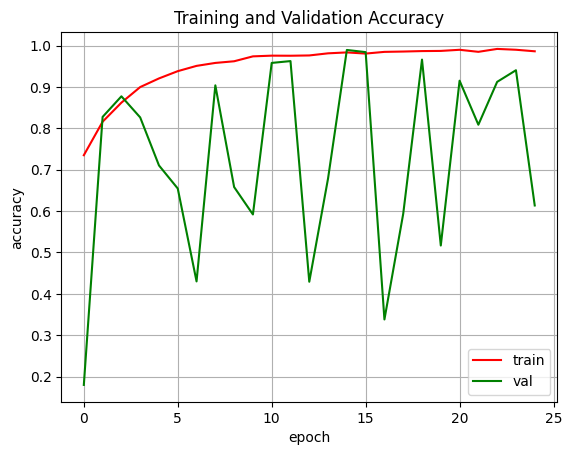

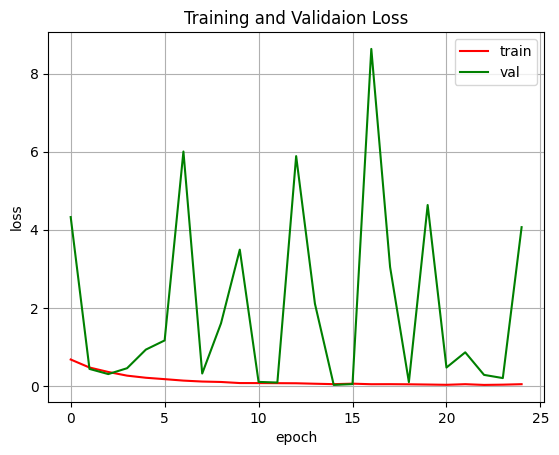

<Figure size 640x480 with 0 Axes>

In [57]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(acc))

plt.plot(epochs, acc, 'red')
plt.plot(epochs, val_acc, 'g')
plt.title('Training and Validation Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='lower right')
plt.grid()
plt.figure()

plt.plot(epochs, loss, 'red')
plt.plot(epochs, val_loss, 'g')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper right')
plt.title('Training and Validaion Loss')
plt.grid()
plt.figure()

# **Confusion Matrix**

Text(0.5, 23.52222222222222, 'Predicted label')

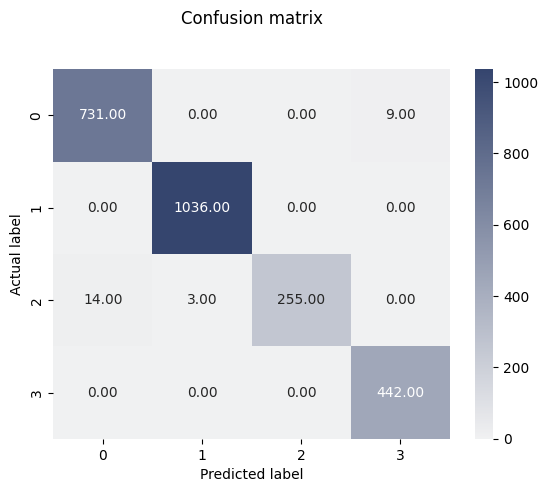

In [39]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['0', '1', '2', '3']
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
p = sns.heatmap(cm, annot=True, fmt='.2f', cmap=sns.light_palette("#35456e", as_cmap=True),
                xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
# plt.savefig('/content/drive/MyDrive/pdfs/ct1_Task_CM.pdf')

Text(0.5, 23.52222222222222, 'Predicted label')

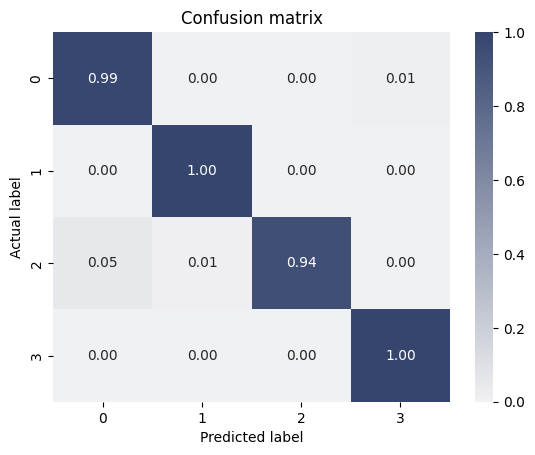

In [41]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['0', '1', '2', '3']
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
cm = cm.astype('float')/cm.sum(axis=1)[:, np.newaxis]
p = sns.heatmap(cm, annot=True, fmt='.2f', cmap=sns.light_palette("#35456e", as_cmap=True),
                xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion matrix', y=1.0)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
# plt.savefig('/content/drive/MyDrive/pdfs/ct1_Task_NCM.pdf')

# **Classification Report**

In [37]:
#import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred, target_names = target_names))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       740
           1       1.00      1.00      1.00      1036
           2       1.00      0.94      0.97       272
           3       0.98      1.00      0.99       442

    accuracy                           0.99      2490
   macro avg       0.99      0.98      0.99      2490
weighted avg       0.99      0.99      0.99      2490



# **ROC Curve**

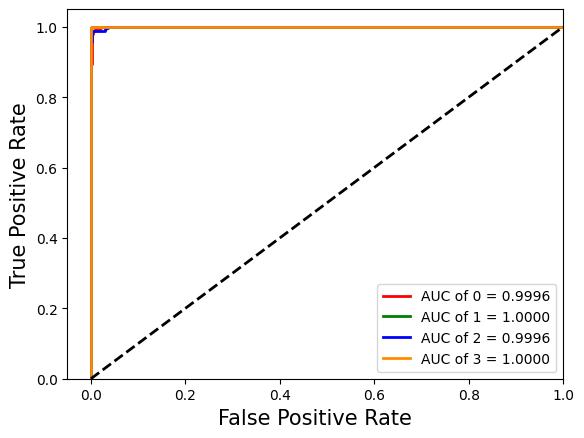

In [46]:
from sklearn.metrics import roc_curve, auc
import itertools
from itertools import cycle
fpr = dict()
tpr = dict()
roc_auc = dict()
lw=2
for i in range(4):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
colors =cycle(['red', 'green', 'blue','darkorange'])
for i, color in zip(range(4), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='AUC of {0} = {1:0.4f}'
             ''.format(i, roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate',fontsize=15)
plt.ylabel('True Positive Rate',fontsize=15)
# plt.title('Receiver operating characteristic for multi-class data')
plt.legend(loc="lower right")
# plt.savefig('/content/drive/MyDrive/pdfs/ct1_Task_ROC.pdf')
plt.show()

In [ ]:
np.save('/content/drive/MyDrive/fpr-tpr_files/ct1_fpr_task.npy', fpr)
np.save('/content/drive/MyDrive/fpr-tpr_files/ct1_tpr_task.npy', tpr)

# **Model Size, FLOPS, and MACS**

In [63]:
import numpy as np
from keras.models import Model
from keras.layers import Input, Conv2D, Concatenate, BatchNormalization, GlobalAveragePooling2D, Dense

def calculate_conv_flops_macs(input_shape, filters, kernel_size, strides):
    flops = 2 * np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)
    macs = np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)
    return flops, macs

input_shape = (128, 128, 3)
eps = 1e-5

input = Input(shape=input_shape)

x1 = Conv2D(32, (3, 3), padding='same', activation='relu')(input)
x1 = BatchNormalization(axis=-1, epsilon=eps)(x1)
x2 = Conv2D(64, (3, 3), padding='same', activation='relu')(x1)
x2 = BatchNormalization(axis=-1, epsilon=eps)(x2)
x3 = Conv2D(128, (3, 3), padding='same', activation='relu')(x2)
x3 = BatchNormalization(axis=-1, epsilon=eps)(x3)
c1 = Concatenate()([x1, x2, x3])

eca_output = eca_module(c1)

x = GlobalAveragePooling2D()(eca_output)

x = Dense(units=512, activation='relu')(x)
x = Dense(units=256, activation='relu')(x)
x = Dense(units=64, activation='relu')(x)
output = Dense(units=4, activation='softmax')(x)

model = Model(inputs=input, outputs=output)

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

flops = 0
macs = 0

layers_config = model.get_config()['layers']

for layer_config in layers_config:
    class_name = layer_config['class_name']
    if class_name == 'Conv2D':
        config = layer_config['config']
        filters = config['filters']
        kernel_size = config['kernel_size']
        strides = config['strides']
        layer_flops, layer_macs = calculate_conv_flops_macs(input_shape, filters, kernel_size, strides)
        flops += layer_flops
        macs += layer_macs

print("Total FLOPs:", flops)
print("Total MACs:", macs)

# Convert FLOPs to GFLOPs
gflops = flops / 1e9

# Convert MACs to GMACs
gmacs = macs / 1e9

print("Total GFLOPs:", gflops)
print("Total GMACs:", gmacs)


224
Total FLOPs: 198180864.0
Total MACs: 99090432.0
Total GFLOPs: 0.198180864
Total GMACs: 0.099090432


In [48]:
# Calculate model size in MB
model_size = model.count_params() * 4 / (1024 * 1024)  # Assuming float32 precision
print("Model Size (MB):", model_size)

Model Size (MB): 1.5824775695800781


# **Trained Feature Visualization**

In [49]:
model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 128, 128,  │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 128, 128,  │     18,496 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_17[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 128, 128,  │     73,856 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        512 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Concatenate)       │ 224)              │            │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 128, 128,  │      3,150 │ concatenate_2[0]… │
│                     │ 14)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 128, 128,  │        210 │ conv2d_19[0][0]   │
│                     │ 14)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │      3,360 │ conv2d_20[0][0]   │
│                     │ 224)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │        225 │ conv2d_21[0][0]   │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_4          │ (None, 128, 128,  │          0 │ conv2d_22[0][0],  │
│ (Multiply)          │ 224)              │            │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 128, 128,  │          0 │ multiply_4[0][0], │
│                     │ 224)              │            │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 224)       │          0 │ add_4[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 112)       │     25,200 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 112)       │          0 │ dense_12[0][0]  

 Total params: 1,243,617 (4.74 MB)

 Trainable params: 414,389 (1.58 MB)

 Non-trainable params: 448 (1.75 KB)

 Optimizer params: 828,780 (3.16 MB)

In [51]:
from keras.models import Model
model = model
layer_name = 'dense_16'
intermediate_layer_model = Model(inputs = model.input, outputs = model.get_layer(layer_name).output)
intermediate_output1 = intermediate_layer_model.predict([X_test])

78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step


W0000 00:00:1717046543.236775      91 graph_launch.cc:671] Fallback to op-by-op mode because memset node breaks graph update


In [52]:
import numpy as np
import pandas as pd
np.savetxt("/kaggle/working/kidney_X_test_Proposed_Features.csv", intermediate_output1, delimiter = ",")

In [53]:
df2 = pd.read_csv("/kaggle/working/kidney_X_test_Proposed_Features.csv", header = None, delimiter = ",")
df2

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,3.074572,0.00000,0.000000,...,1.073008,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.000000
1,0.446628,0.000000,3.736149,0.000000,6.362123,0.067511,0.0,0.000000,0.00000,0.000000,...,0.000000,0.000000,5.299478,0.000000,0.000000,0.0,0.0,0.000000,0.0,6.599007
2,0.000000,0.000000,1.883630,0.000000,1.817356,0.000000,0.0,0.000000,0.00000,4.587730,...,1.794999,0.000000,0.261270,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.856519
3,0.327432,0.000000,4.218345,0.000000,6.398786,0.249820,0.0,0.000000,0.00000,0.000000,...,0.000000,0.000000,5.483645,0.000000,0.000000,0.0,0.0,0.000000,0.0,6.691500
4,0.000000,0.000000,0.000000,0.000000,4.708205,0.000000,0.0,0.000000,0.00000,0.000000,...,0.000000,0.000000,4.191113,0.000000,10.095185,0.0,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2485,0.000000,0.000000,0.000000,0.000000,1.060824,0.000000,0.0,0.000000,0.00000,0.000000,...,0.000000,0.000000,3.077605,0.000000,10.487057,0.0,0.0,0.430779,0.0,0.000000
2486,0.000000,0.426458,2.633671,0.000000,1.120725,0.000000,0.0,0.000000,0.00000,1.985520,...,1.992249,0.353414,0.610246,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.789315
2487,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.00000,1.896881,...,0.000000,0.924334,0.000000,0.000000,1.578953,0.0,0.0,0.000000,0.0,0.000000
2488,1.493392,0.000000,0.000000,0.000000,0.000000,3.124014,0.0,1.925188,2.62573,0.000000,...,3.537570,0.000000,0.000000,0.000000,0.000000,0.0,0.0,2.449289,0.0,0.000000


In [54]:
df3 = pd.read_csv("/kaggle/working/y_test.csv", header = None, delimiter = ",")
df3

,0
0,3.0
1,2.0
2,0.0
3,2.0
4,1.0
...,...
2485,1.0
2486,0.0
2487,0.0
2488,3.0


In [55]:
import numpy as np
from sklearn.manifold import TSNE
X = np.array(df2)
X_embedded = TSNE(n_components=2).fit_transform(X)

In [56]:
import plotly.express as px
fig = px.scatter(X_embedded, x =0, y = 1, color=df3[0], width=600, height=500)
fig.show()